In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Charger l'échantillon longitudinal
fichier = Path("data/santander_echantillon.csv")

df = pd.read_csv(
    fichier,
    low_memory=False
)

# Convertir les dates
df["fecha_dato"] = pd.to_datetime(
    df["fecha_dato"]
)

# Trier les observations
df = df.sort_values(
    ["ncodpers", "fecha_dato"]
).reset_index(drop=True)

print("Dimensions :", df.shape)
print("Clients :", df["ncodpers"].nunique())
print("Mois :", df["fecha_dato"].nunique())

Dimensions : (285734, 48)
Clients : 20000
Mois : 17


In [2]:
# Sélectionner les 7 produits
produits_modelises = [
    "ind_recibo_ult1",
    "ind_nom_pens_ult1",
    "ind_nomina_ult1",
    "ind_cco_fin_ult1",
    "ind_tjcr_fin_ult1",
    "ind_cno_fin_ult1",
    "ind_ecue_fin_ult1"
]

# Convertir les indicateurs en nombres
df[produits_modelises] = df[
    produits_modelises
].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Produits sélectionnés :", len(produits_modelises))

Produits sélectionnés : 7


In [3]:
# Nous créeons les variables que nos modèles devront prédire. Pour chaque observation au mois \(t\),
# nous rechercherons la détention des produits au mois \(t+1\).
# Date de l'observation suivante
date_suivante = (
    df.groupby("ncodpers")["fecha_dato"]
    .shift(-1)
)

# Vérifier que le mois suivant est consécutif
mois_actuel = df["fecha_dato"].dt.to_period("M")
mois_suivant = date_suivante.dt.to_period("M")

consecutif = (
    (mois_actuel + 1) == mois_suivant
)

# Produits détenus au mois suivant
produits_suivants = (
    df.groupby("ncodpers")[produits_modelises]
    .shift(-1)
)

# Construire les acquisitions futures
cibles = pd.DataFrame(index=df.index)

for produit in produits_modelises:

    cible = (
        (df[produit] == 0)
        & (produits_suivants[produit] == 1)
    ).astype("Int64")

    valide = (
        consecutif
        & df[produit].notna()
        & produits_suivants[produit].notna()
    )

    cibles["cible_" + produit] = cible.where(valide)

print("Dimensions des cibles :", cibles.shape)

display(cibles.head())

Dimensions des cibles : (285734, 7)


,cible_ind_recibo_ult1,cible_ind_nom_pens_ult1,cible_ind_nomina_ult1,cible_ind_cco_fin_ult1,cible_ind_tjcr_fin_ult1,cible_ind_cno_fin_ult1,cible_ind_ecue_fin_ult1
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0
4,0,0,0,0,0,0,0


In [4]:
print("Acquisitions futures par produit :")

display(
    cibles.sum()
    .sort_values(ascending=False)
    .to_frame("Nombre d'acquisitions")
)

print("\nNombre de valeurs manquantes :")

display(
    cibles.isna()
    .sum()
    .to_frame("Valeurs manquantes")
)

Acquisitions futures par produit :


,Nombre d'acquisitions
cible_ind_recibo_ult1,3350
cible_ind_nom_pens_ult1,1927
cible_ind_nomina_ult1,1691
cible_ind_cco_fin_ult1,1486
cible_ind_tjcr_fin_ult1,1457
cible_ind_cno_fin_ult1,802
cible_ind_ecue_fin_ult1,570



Nombre de valeurs manquantes :


,Valeurs manquantes
cible_ind_recibo_ult1,20174
cible_ind_nom_pens_ult1,20466
cible_ind_nomina_ult1,20466
cible_ind_cco_fin_ult1,20174
cible_ind_tjcr_fin_ult1,20174
cible_ind_cno_fin_ult1,20174
cible_ind_ecue_fin_ult1,20174


In [5]:
# Identifier les 24 indicateurs de produits
tous_produits = [
    col for col in df.columns
    if col.endswith("_ult1")
]

# Variables explicatives de départ
variables_profil = [
    "age",
    "antiguedad",
    "renta",
    "segmento",
    "ind_actividad_cliente"
]

variables_X = variables_profil + tous_produits

# Construire la matrice explicative
X = df[variables_X].copy()

# Convertir les variables numériques
numeriques = [
    "age",
    "antiguedad",
    "renta"
] + tous_produits

X[numeriques] = X[numeriques].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Dimensions de X :", X.shape)

display(X.head())

Dimensions de X : (285734, 29)


,age,antiguedad,renta,segmento,ind_actividad_cliente,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,...,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,0,0,...,0,0,0,0,1,1,0,0.0,0.0,0
1,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,0,0,...,0,0,0,0,0,1,0,0.0,0.0,0
2,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,0,0,...,0,0,0,0,0,1,0,0.0,0.0,0
3,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,0,0,...,0,0,0,0,0,1,0,0.0,0.0,0
4,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,0,0,...,0,0,0,0,1,1,0,0.0,0.0,0


In [6]:
# Associer les variables explicatives aux cibles
donnees_ml = pd.concat(
    [
        df[["ncodpers", "fecha_dato"]],
        X,
        cibles
    ],
    axis=1
)

# Ajouter le mois à prédire
donnees_ml["mois_cible"] = (
    donnees_ml["fecha_dato"]
    + pd.DateOffset(months=1)
).dt.to_period("M")

print("Dimensions :", donnees_ml.shape)

display(donnees_ml.head())

Dimensions : (285734, 39)


,ncodpers,fecha_dato,age,antiguedad,renta,segmento,ind_actividad_cliente,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,...,ind_nom_pens_ult1,ind_recibo_ult1,cible_ind_recibo_ult1,cible_ind_nom_pens_ult1,cible_ind_nomina_ult1,cible_ind_cco_fin_ult1,cible_ind_tjcr_fin_ult1,cible_ind_cno_fin_ult1,cible_ind_ecue_fin_ult1,mois_cible
0,15889,2015-01-28,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,...,0.0,0,0,0,0,0,0,0,0,2015-02
1,15889,2015-02-28,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,...,0.0,0,0,0,0,0,0,0,0,2015-03
2,15889,2015-03-28,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,...,0.0,0,0,0,0,0,0,0,0,2015-04
3,15889,2015-04-28,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,...,0.0,0,0,0,0,0,1,0,0,2015-05
4,15889,2015-05-28,56.0,245.0,326124.9,01 - TOP,1.0,0,0,1,...,0.0,0,0,0,0,0,0,0,0,2015-06


In [7]:
# Périodes selon le mois d'acquisition à prédire
mois = donnees_ml["mois_cible"]

conditions = [
    mois <= pd.Period("2015-12", freq="M"),
    (mois >= pd.Period("2016-01", freq="M"))
    & (mois <= pd.Period("2016-03", freq="M")),
    (mois >= pd.Period("2016-04", freq="M"))
    & (mois <= pd.Period("2016-05", freq="M"))
]

choix = [
    "Entrainement",
    "Validation",
    "Test"
]

donnees_ml["periode"] = np.select(
    conditions,
    choix,
    default="Hors_periode"
)

# Nombre de lignes par période
print("Répartition des observations :")

display(
    donnees_ml["periode"].value_counts()
)

Répartition des observations :


periode
Entrainement    170197
Validation       57389
Test             38701
Hors_periode     19447
Name: count, dtype: int64

In [8]:
resultats = []

for produit in produits_modelises:

    cible = "cible_" + produit

    # Clients ne possédant pas le produit
    # et dont l'acquisition future est connue
    eligibles = (
        (donnees_ml[produit] == 0)
        & donnees_ml[cible].notna()
        & donnees_ml["periode"].isin(
            ["Entrainement", "Validation", "Test"]
        )
    )

    for periode in [
        "Entrainement",
        "Validation",
        "Test"
    ]:

        masque = (
            eligibles
            & (donnees_ml["periode"] == periode)
        )

        n = masque.sum()

        acquisitions = (
            donnees_ml.loc[masque, cible].sum()
        )

        taux = (
            acquisitions / n * 100
            if n > 0 else np.nan
        )

        resultats.append({
            "Produit": produit,
            "Periode": periode,
            "Observations": n,
            "Acquisitions": acquisitions,
            "Taux acquisition (%)": taux
        })

tableau_ml = pd.DataFrame(resultats)

display(tableau_ml)

,Produit,Periode,Observations,Acquisitions,Taux acquisition (%)
0,ind_recibo_ult1,Entrainement,146887,2235,1.521578
1,ind_recibo_ult1,Validation,50373,680,1.349930
2,ind_recibo_ult1,Test,33936,435,1.281825
3,ind_nom_pens_ult1,Entrainement,158349,1260,0.795711
4,ind_nom_pens_ult1,Validation,54161,454,0.838242
5,ind_nom_pens_ult1,Test,36462,213,0.584170
6,ind_nomina_ult1,Entrainement,159270,1117,0.701325
7,ind_nomina_ult1,Validation,54400,373,0.685662
8,ind_nomina_ult1,Test,36646,201,0.548491
9,ind_cco_fin_ult1,Entrainement,53029,1007,1.898961


In [9]:
# Produit à prédire
produit = "ind_tjcr_fin_ult1"
cible = "cible_" + produit

# Conserver uniquement les clients qui ne possèdent
# pas déjà le produit et dont la cible est connue
masque = (
    (donnees_ml[produit] == 0)
    & donnees_ml[cible].notna()
    & donnees_ml["periode"].isin(
        ["Entrainement", "Validation", "Test"]
    )
)

data_carte = donnees_ml.loc[masque].copy()

# Séparer les périodes
train = data_carte[
    data_carte["periode"] == "Entrainement"
]

validation = data_carte[
    data_carte["periode"] == "Validation"
]

test = data_carte[
    data_carte["periode"] == "Test"
]

print("Entraînement :", train.shape)
print("Validation :", validation.shape)
print("Test :", test.shape)

Entraînement : (161334, 40)
Validation : (55028, 40)
Test : (37182, 40)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

variables_num = [
    "age",
    "antiguedad",
    "renta"
] + tous_produits

variables_cat = [
    "segmento",
    "ind_actividad_cliente"
]

# Pipeline numérique
pipeline_num = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# Pipeline catégoriel
pipeline_cat = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

# Prétraitement complet
preprocesseur = ColumnTransformer([
    ("num", pipeline_num, variables_num),
    ("cat", pipeline_cat, variables_cat)
])

print("Préprocesseur créé avec succès")

Préprocesseur créé avec succès


In [11]:
from sklearn.linear_model import LogisticRegression

# Pipeline complet
modele_carte = Pipeline([
    ("preparation", preprocesseur),
    ("classification", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Variables d'entraînement
X_train = train[variables_X]
y_train = train[cible].astype(int)

# Entraînement
modele_carte.fit(X_train, y_train)

print("Modèle entraîné avec succès")

Modèle entraîné avec succès


In [12]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)

X_val = validation[variables_X]
y_val = validation[cible].astype(int)

# Scores prédits
probabilites = modele_carte.predict_proba(X_val)[:, 1]

# Classification au seuil 0,5 (provisoire)
predictions = (probabilites >= 0.5).astype(int)

print("ROC-AUC :", roc_auc_score(y_val, probabilites))

print(
    "Average Precision :",
    average_precision_score(y_val, probabilites)
)

print(
    "Précision :",
    precision_score(y_val, predictions, zero_division=0)
)

print(
    "Rappel :",
    recall_score(y_val, predictions, zero_division=0)
)

ROC-AUC : 0.9156266702178653
Average Precision : 0.05510747120162497
Précision : 0.021771109149749928
Rappel : 0.8705882352941177


In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

seuils = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

resultats_seuils = []

for seuil in seuils:

    predictions = (
        probabilites >= seuil
    ).astype(int)

    resultats_seuils.append({
        "Seuil": seuil,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Rappel": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Predictions positives": predictions.sum()
    })

tableau_seuils = pd.DataFrame(resultats_seuils)

display(tableau_seuils)

,Seuil,Precision,Rappel,F1-score,Predictions positives
0,0.10,0.011082,0.952941,0.021910,21927
1,0.30,0.015156,0.949020,0.029836,15967
2,0.50,0.021771,0.870588,0.042480,10197
3,0.70,0.041269,0.729412,0.078118,4507
4,0.90,0.073236,0.431373,0.125213,1502
5,0.95,0.074126,0.207843,0.109278,715
6,0.99,0.051282,0.007843,0.013605,39


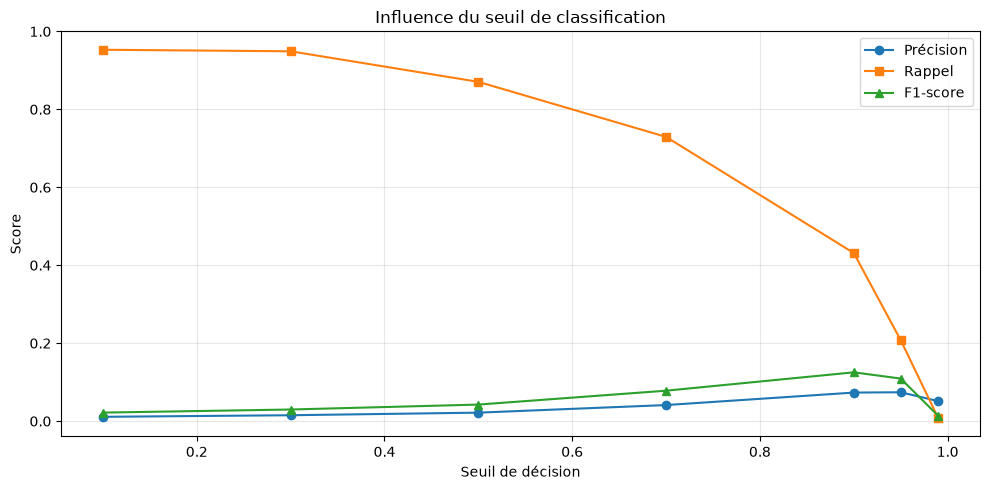

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Precision"],
    marker="o",
    label="Précision"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Rappel"],
    marker="s",
    label="Rappel"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["F1-score"],
    marker="^",
    label="F1-score"
)

plt.title("Influence du seuil de classification")
plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
import numpy as np

# Trier les observations par score décroissant
indices_tries = np.argsort(-probabilites)

y_tries = np.asarray(y_val)[indices_tries]

resultats_topk = []

for k in [100, 250, 500, 1000, 2000]:

    precision_k = y_tries[:k].mean()

    rappel_k = y_tries[:k].sum() / y_val.sum()

    resultats_topk.append({
        "Top K": k,
        "Acquisitions reelles": int(y_tries[:k].sum()),
        "Precision@K": precision_k,
        "Recall@K": rappel_k
    })

tableau_topk = pd.DataFrame(resultats_topk)

display(tableau_topk)

,Top K,Acquisitions reelles,Precision@K,Recall@K
0,100,7,0.070,0.027451
1,250,13,0.052,0.050980
2,500,35,0.070,0.137255
3,1000,76,0.076,0.298039
4,2000,132,0.066,0.517647


In [16]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Fréquence des acquisitions en entraînement
frequence_train = y_train.mean()

# Modèle de référence : même score pour tous
scores_reference = np.full(
    len(y_val),
    frequence_train
)

comparaison = pd.DataFrame({
    "Modele": [
        "Reference constante",
        "Regression logistique"
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, scores_reference),
        roc_auc_score(y_val, probabilites)
    ],
    "Average Precision": [
        average_precision_score(y_val, scores_reference),
        average_precision_score(y_val, probabilites)
    ]
})

display(comparaison)

,Modele,ROC-AUC,Average Precision
0,Reference constante,0.500000,0.004634
1,Regression logistique,0.915627,0.055107


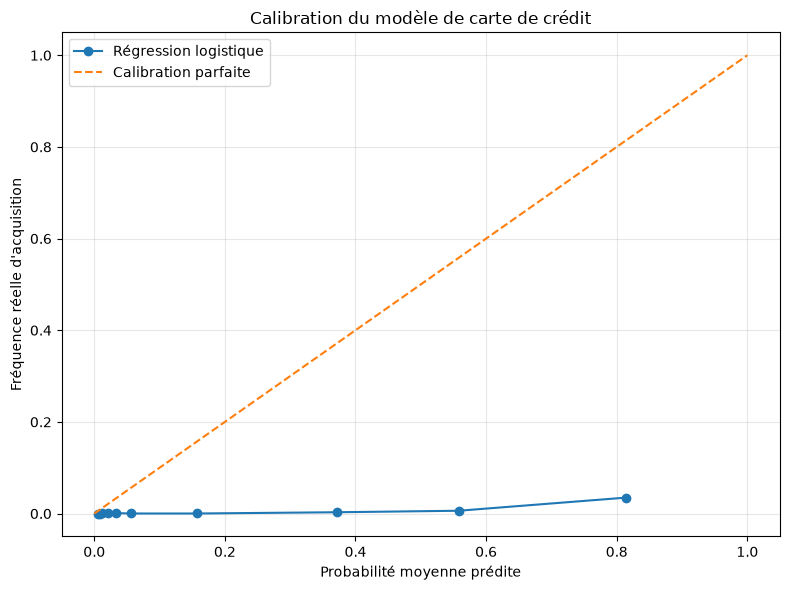

In [17]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fraction_positifs, probabilites_moyennes = calibration_curve(
    y_val,
    probabilites,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    probabilites_moyennes,
    fraction_positifs,
    marker="o",
    label="Régression logistique"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibration parfaite"
)

plt.xlabel("Probabilité moyenne prédite")
plt.ylabel("Fréquence réelle d'acquisition")
plt.title("Calibration du modèle de carte de crédit")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Nouveau modèle sans pondération des classes
modele_sans_poids = Pipeline([
    ("preparation", clone(preprocesseur)),
    ("classification", LogisticRegression(
        class_weight=None,
        max_iter=1000,
        random_state=42
    ))
])

modele_sans_poids.fit(X_train, y_train)

print("Modèle sans pondération entraîné.")

Modèle sans pondération entraîné.


In [19]:
# Calibration : janvier et février 2016
calibration = validation[
    validation["mois_cible"].isin([
        pd.Period("2016-01", freq="M"),
        pd.Period("2016-02", freq="M")
    ])
].copy()

# Comparaison : mars 2016
evaluation = validation[
    validation["mois_cible"] == pd.Period(
        "2016-03", freq="M"
    )
].copy()

X_cal = calibration[variables_X]
y_cal = calibration[cible].astype(int)

X_eval = evaluation[variables_X]
y_eval = evaluation[cible].astype(int)

print("Calibration :", len(X_cal))
print("Comparaison :", len(X_eval))

print("Acquisitions calibration :", y_cal.sum())
print("Acquisitions comparaison :", y_eval.sum())

Calibration : 36560
Comparaison : 18468
Acquisitions calibration : 166
Acquisitions comparaison : 89


In [20]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Modèle équilibré déjà entraîné
modele_equilibre_calibre = CalibratedClassifierCV(
    estimator=FrozenEstimator(modele_carte),
    method="sigmoid"
)

# Modèle sans pondération déjà entraîné
modele_normal_calibre = CalibratedClassifierCV(
    estimator=FrozenEstimator(modele_sans_poids),
    method="sigmoid"
)

# Calibration sur janvier et février 2016
modele_equilibre_calibre.fit(X_cal, y_cal)

modele_normal_calibre.fit(X_cal, y_cal)

print("Calibration terminée avec succès.")

Calibration terminée avec succès.


In [21]:
# Vérifier les probabilités calibrées

proba_equilibre = (
    modele_equilibre_calibre
    .predict_proba(X_eval)[:, 1]
)

proba_normal = (
    modele_normal_calibre
    .predict_proba(X_eval)[:, 1]
)

print("Probabilité moyenne - modèle équilibré :",
      proba_equilibre.mean())

print("Probabilité moyenne - modèle sans poids :",
      proba_normal.mean())

print("Fréquence réelle des acquisitions :",
      y_eval.mean())

Probabilité moyenne - modèle équilibré : 0.004638785338501203
Probabilité moyenne - modèle sans poids : 0.004667881113004981
Fréquence réelle des acquisitions : 0.004819146632012129


In [22]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

modeles = {
    "Equilibre non calibre": modele_carte,
    "Sans poids non calibre": modele_sans_poids,
    "Equilibre calibre": modele_equilibre_calibre,
    "Sans poids calibre": modele_normal_calibre
}

resultats = []

for nom, modele in modeles.items():

    proba = modele.predict_proba(X_eval)[:, 1]

    resultats.append({
        "Modele": nom,
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "Average Precision": average_precision_score(
            y_eval, proba
        ),
        "Brier Score": brier_score_loss(y_eval, proba),
        "Probabilite moyenne": proba.mean(),
        "Frequence reelle": y_eval.mean()
    })

comparaison_calibration = pd.DataFrame(resultats)

display(
    comparaison_calibration.sort_values(
        "Brier Score"
    )
)

,Modele,ROC-AUC,Average Precision,Brier Score,Probabilite moyenne,Frequence reelle
3,Sans poids calibre,0.906786,0.059816,0.004645,0.004668,0.004819
1,Sans poids non calibre,0.906786,0.059816,0.004658,0.005655,0.004819
2,Equilibre calibre,0.912574,0.060320,0.004663,0.004639,0.004819
0,Equilibre non calibre,0.912574,0.060320,0.114808,0.205383,0.004819


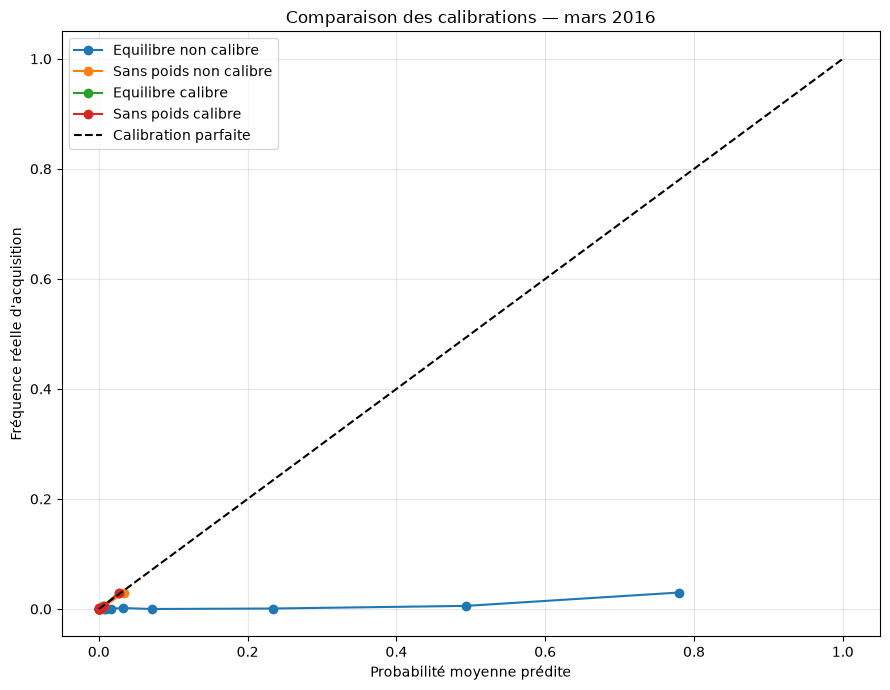

In [23]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

for nom, modele in modeles.items():

    proba = modele.predict_proba(X_eval)[:, 1]

    freq, pred = calibration_curve(
        y_eval,
        proba,
        n_bins=8,
        strategy="quantile"
    )

    plt.plot(
        pred,
        freq,
        marker="o",
        label=nom
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="black",
    label="Calibration parfaite"
)

plt.xlabel("Probabilité moyenne prédite")
plt.ylabel("Fréquence réelle d'acquisition")
plt.title("Comparaison des calibrations — mars 2016")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

modeles_bancaires = {}
resultats_bancaires = []

for produit in produits_modelises:

    print("\nProduit :", produit)

    cible_produit = "cible_" + produit

    # Clients sans le produit et cible connue
    masque = (
        (donnees_ml[produit] == 0)
        & donnees_ml[cible_produit].notna()
        & donnees_ml["periode"].isin([
            "Entrainement", "Validation"
        ])
    )

    donnees_produit = donnees_ml.loc[masque].copy()

    train_p = donnees_produit[
        donnees_produit["periode"] == "Entrainement"
    ]

    cal_p = donnees_produit[
        donnees_produit["mois_cible"].isin([
            pd.Period("2016-01", freq="M"),
            pd.Period("2016-02", freq="M")
        ])
    ]

    eval_p = donnees_produit[
        donnees_produit["mois_cible"] ==
        pd.Period("2016-03", freq="M")
    ]

    X_train_p = train_p[variables_X]
    y_train_p = train_p[cible_produit].astype(int)

    X_cal_p = cal_p[variables_X]
    y_cal_p = cal_p[cible_produit].astype(int)

    X_eval_p = eval_p[variables_X]
    y_eval_p = eval_p[cible_produit].astype(int)

    if (
        y_train_p.nunique() < 2
        or y_cal_p.nunique() < 2
        or y_eval_p.nunique() < 2
    ):
        print("Classes insuffisantes, produit ignoré.")
        continue

    # Modèle équilibré
    modele = Pipeline([
        ("preparation", clone(preprocesseur)),
        ("classification", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ])

    modele.fit(X_train_p, y_train_p)

    # Calibration sigmoïde
    modele_calibre = CalibratedClassifierCV(
        estimator=FrozenEstimator(modele),
        method="sigmoid"
    )

    modele_calibre.fit(X_cal_p, y_cal_p)

    # Évaluation sur mars 2016
    proba = modele_calibre.predict_proba(
        X_eval_p
    )[:, 1]

    resultats_bancaires.append({
        "Produit": produit,
        "ROC-AUC": roc_auc_score(y_eval_p, proba),
        "Average Precision": average_precision_score(
            y_eval_p, proba
        ),
        "Brier Score": brier_score_loss(
            y_eval_p, proba
        ),
        "Acquisitions evaluation": int(y_eval_p.sum())
    })

    modeles_bancaires[produit] = modele_calibre

    print("Modèle entraîné et calibré.")

comparaison_produits = pd.DataFrame(
    resultats_bancaires
)

display(comparaison_produits)


Produit : ind_recibo_ult1
Modèle entraîné et calibré.

Produit : ind_nom_pens_ult1
Modèle entraîné et calibré.

Produit : ind_nomina_ult1
Modèle entraîné et calibré.

Produit : ind_cco_fin_ult1
Modèle entraîné et calibré.

Produit : ind_tjcr_fin_ult1
Modèle entraîné et calibré.

Produit : ind_cno_fin_ult1
Modèle entraîné et calibré.

Produit : ind_ecue_fin_ult1
Modèle entraîné et calibré.


,Produit,ROC-AUC,Average Precision,Brier Score,Acquisitions evaluation
0,ind_recibo_ult1,0.882568,0.087105,0.012841,226
1,ind_nom_pens_ult1,0.945877,0.170319,0.006209,123
2,ind_nomina_ult1,0.943203,0.163469,0.005933,120
3,ind_cco_fin_ult1,0.853991,0.091311,0.014241,113
4,ind_tjcr_fin_ult1,0.912574,0.060320,0.004663,89
5,ind_cno_fin_ult1,0.904805,0.085099,0.002475,44
6,ind_ecue_fin_ult1,0.873183,0.050660,0.002189,39


,Produit,ROC-AUC,Average Precision,Brier Score,Acquisitions evaluation
1,ind_nom_pens_ult1,0.945877,0.170319,0.006209,123
2,ind_nomina_ult1,0.943203,0.163469,0.005933,120
3,ind_cco_fin_ult1,0.853991,0.091311,0.014241,113
0,ind_recibo_ult1,0.882568,0.087105,0.012841,226
5,ind_cno_fin_ult1,0.904805,0.085099,0.002475,44
4,ind_tjcr_fin_ult1,0.912574,0.060320,0.004663,89
6,ind_ecue_fin_ult1,0.873183,0.050660,0.002189,39


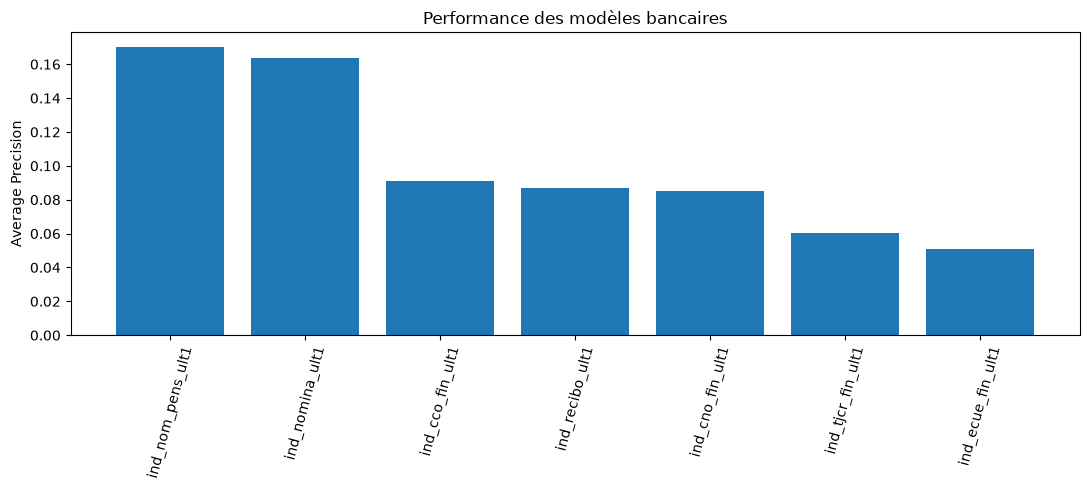

In [25]:
comparaison_produits = comparaison_produits.sort_values(
    "Average Precision",
    ascending=False
)

display(comparaison_produits)

# Visualisation
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.bar(
    comparaison_produits["Produit"],
    comparaison_produits["Average Precision"]
)

plt.title("Performance des modèles bancaires")
plt.ylabel("Average Precision")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [26]:
noms_produits = {
    "ind_recibo_ult1": "Prélèvements automatiques",
    "ind_nom_pens_ult1": "Domiciliation de pension",
    "ind_nomina_ult1": "Domiciliation de salaire",
    "ind_cco_fin_ult1": "Compte courant",
    "ind_tjcr_fin_ult1": "Carte de crédit",
    "ind_cno_fin_ult1": "Compte de paie",
    "ind_ecue_fin_ult1": "E-account"
}

print("Catalogue de produits créé.")

Catalogue de produits créé.


In [27]:
def recommander_produits(profil_client, top_n=3):

    # Transformer le profil en DataFrame
    client = pd.DataFrame([profil_client])

    # Conserver les variables explicatives
    X_client = client[variables_X]

    recommandations = []

    for produit, modele in modeles_bancaires.items():

        # Ne pas recommander un produit déjà détenu
        detention = pd.to_numeric(
            client[produit],
            errors="coerce"
        ).iloc[0]

        # Exclure les produits détenus ou inconnus
        if pd.isna(detention) or detention != 0:
            continue

        # Probabilité d'acquisition
        probabilite = modele.predict_proba(
            X_client
        )[0, 1]

        recommandations.append({
            "Produit": noms_produits[produit],
            "Probabilite": probabilite
        })

    # Trier les recommandations
    recommandations = sorted(
        recommandations,
        key=lambda x: x["Probabilite"],
        reverse=True
    )

    return pd.DataFrame(
        recommandations[:top_n],
        columns=["Produit", "Probabilite"]
    )

In [28]:
# Sélectionner un client de mars 2016
clients_mars = df[
    df["fecha_dato"] == pd.Timestamp("2016-03-28")
]

# Prendre le premier client
profil_client = clients_mars.iloc[0].to_dict()

print("Identifiant du client :",
      profil_client["ncodpers"])

# Obtenir les recommandations
recommandations = recommander_produits(
    profil_client,
    top_n=3
)

display(recommandations)

Identifiant du client : 15889


,Produit,Probabilite
0,Prélèvements automatiques,0.088422
1,E-account,0.008174
2,Domiciliation de pension,0.003366


In [29]:
recommandations_affichage = recommandations.copy()

recommandations_affichage["Probabilite"] = (
    recommandations_affichage["Probabilite"]
    .map(lambda p: f"{p * 100:.2f} %")
)

print("Top 3 des recommandations BankReco")

display(recommandations_affichage)

Top 3 des recommandations BankReco


,Produit,Probabilite
0,Prélèvements automatiques,8.84 %
1,E-account,0.82 %
2,Domiciliation de pension,0.34 %


In [30]:
import pandas as pd
import numpy as np

# Sélectionner les observations dont la cible
# correspond à avril ou mai 2016

mois_test = [
    pd.Period("2016-04", freq="M"),
    pd.Period("2016-05", freq="M")
]

test_final = donnees_ml[
    donnees_ml["mois_cible"].isin(mois_test)
].copy()

print("Observations de test :", len(test_final))

print(
    "Clients distincts :",
    test_final["ncodpers"].nunique()
)

print(
    "Mois cibles :",
    test_final["mois_cible"].unique()
)

Observations de test : 38701
Clients distincts : 19411
Mois cibles : <PeriodArray>
['2016-04', '2016-05']
Length: 2, dtype: period[M]


In [31]:
# Matrice des variables explicatives
X_test = test_final[variables_X]

# Tableau des scores
scores_test = pd.DataFrame(
    index=test_final.index
)

for produit, modele in modeles_bancaires.items():

    # Probabilités calibrées
    probabilites = modele.predict_proba(
        X_test
    )[:, 1]

    scores_test[produit] = probabilites

    # Exclure les produits déjà détenus
    detention = pd.to_numeric(
        test_final[produit],
        errors="coerce"
    )

    scores_test.loc[
        detention.isna() | (detention != 0),
        produit
    ] = np.nan

print("Dimensions des scores :", scores_test.shape)

display(scores_test.head())

Dimensions des scores : (38701, 7)


,ind_recibo_ult1,ind_nom_pens_ult1,ind_nomina_ult1,ind_cco_fin_ult1,ind_tjcr_fin_ult1,ind_cno_fin_ult1,ind_ecue_fin_ult1
14,0.088422,0.003366,0.001839,NaN,NaN,0.001948,0.008174
15,0.034381,0.001718,0.000867,NaN,0.013108,0.000892,0.003138
25,0.000404,0.000291,0.000168,0.002324,0.000600,0.000444,0.000784
26,0.000403,0.000290,0.000167,0.002304,0.000603,0.000442,0.000782
42,0.017647,0.001039,0.000583,NaN,0.009898,0.000738,0.001255


In [32]:
# Classement des produits par observation
top3_test = scores_test.apply(
    lambda ligne: ligne.nlargest(3).index.tolist(),
    axis=1
)

# Présentation
resultats_recommandations = test_final[
    ["ncodpers", "fecha_dato", "mois_cible"]
].copy()

resultats_recommandations["Top_3"] = top3_test

display(resultats_recommandations.head(10))

,ncodpers,fecha_dato,mois_cible,Top_3
14,15889,2016-03-28,2016-04,"[ind_recibo_ult1, ind_ecue_fin_ult1, ind_nom_p..."
15,15889,2016-04-28,2016-05,"[ind_recibo_ult1, ind_tjcr_fin_ult1, ind_ecue_..."
25,16338,2016-03-28,2016-04,"[ind_cco_fin_ult1, ind_ecue_fin_ult1, ind_tjcr..."
26,16338,2016-04-28,2016-05,"[ind_cco_fin_ult1, ind_ecue_fin_ult1, ind_tjcr..."
42,16539,2016-03-28,2016-04,"[ind_recibo_ult1, ind_tjcr_fin_ult1, ind_ecue_..."
43,16539,2016-04-28,2016-05,"[ind_recibo_ult1, ind_tjcr_fin_ult1, ind_ecue_..."
59,16592,2016-03-28,2016-04,"[ind_tjcr_fin_ult1, ind_recibo_ult1, ind_nom_p..."
60,16592,2016-04-28,2016-05,"[ind_tjcr_fin_ult1, ind_recibo_ult1, ind_nom_p..."
76,16773,2016-03-28,2016-04,"[ind_recibo_ult1, ind_tjcr_fin_ult1, ind_ecue_..."
77,16773,2016-04-28,2016-05,"[ind_recibo_ult1, ind_tjcr_fin_ult1, ind_ecue_..."


In [33]:
# Colonnes des acquisitions futures
colonnes_cibles = [
    "cible_" + p
    for p in produits_modelises
]

# Tableau des acquisitions réelles
acquisitions_test = test_final[
    colonnes_cibles
].copy()

# Vérifier les cibles disponibles
print("Valeurs manquantes par cible :")

display(
    acquisitions_test.isna().sum()
)

Valeurs manquantes par cible :


cible_ind_recibo_ult1      63
cible_ind_nom_pens_ult1    63
cible_ind_nomina_ult1      63
cible_ind_cco_fin_ult1     63
cible_ind_tjcr_fin_ult1    63
cible_ind_cno_fin_ult1     63
cible_ind_ecue_fin_ult1    63
dtype: int64

In [34]:
resultats_evaluation = []

for idx in test_final.index:

    recommandations = top3_test.loc[idx]

    # Produits dont la cible est connue
    produits_valides = [
        p for p in produits_modelises
        if pd.notna(
            test_final.loc[idx, "cible_" + p]
        )
        and pd.notna(scores_test.loc[idx, p])
    ]

    recommandations_valides = [
        p for p in recommandations
        if p in produits_valides
    ]

    acquisitions_reelles = [
        p for p in produits_valides
        if test_final.loc[idx, "cible_" + p] == 1
    ]

    hits = len(
        set(recommandations_valides)
        & set(acquisitions_reelles)
    )

    precision = (
        hits / len(recommandations_valides)
        if recommandations_valides
        else np.nan
    )

    rappel = (
        hits / len(acquisitions_reelles)
        if acquisitions_reelles
        else np.nan
    )

    hit_rate = (
        int(hits > 0)
        if acquisitions_reelles
        else np.nan
    )

    resultats_evaluation.append({
        "Precision@3": precision,
        "Recall@3": rappel,
        "Hit@3": hit_rate,
        "Acquisitions": len(acquisitions_reelles),
        "Recommandations": len(recommandations_valides)
    })

evaluation_top3 = pd.DataFrame(
    resultats_evaluation
)

print("Precision@3 moyenne :",
      evaluation_top3["Precision@3"].mean())

print("Recall@3 moyen :",
      evaluation_top3["Recall@3"].mean())

print("Hit Rate@3 :",
      evaluation_top3["Hit@3"].mean())

print(
    "Observations avec au moins une acquisition :",
    (evaluation_top3["Acquisitions"] > 0).sum()
)

Precision@3 moyenne : 0.011348914339016426
Recall@3 moyen : 0.927315233785822
Hit Rate@3 : 0.9529411764705882
Observations avec au moins une acquisition : 1105


In [35]:
# Conserver les observations évaluables
evaluation_valide = evaluation_top3[
    evaluation_top3["Recommandations"] > 0
].copy()

# Nombre total de recommandations
total_recommandations = (
    evaluation_valide["Recommandations"].sum()
)

# Nombre total d'acquisitions
total_acquisitions = (
    evaluation_valide["Acquisitions"].sum()
)

# Retrouver le nombre de recommandations correctes
# à partir de la précision individuelle
total_hits = (
    evaluation_valide["Precision@3"]
    * evaluation_valide["Recommandations"]
).sum()

precision_globale = (
    total_hits / total_recommandations
)

rappel_global = (
    total_hits / total_acquisitions
    if total_acquisitions > 0 else np.nan
)

print("Recommandations :", total_recommandations)
print("Acquisitions :", total_acquisitions)
print("Recommandations correctes :", int(round(total_hits)))

print(
    "Précision globale :",
    round(precision_globale * 100, 3), "%"
)

print(
    "Rappel global :",
    round(rappel_global * 100, 3), "%"
)

Recommandations : 114445
Acquisitions : 1410
Recommandations correctes : 1276
Précision globale : 1.115 %
Rappel global : 90.496 %


In [36]:
# Données d'entraînement uniquement
train_popularite = donnees_ml[
    donnees_ml["periode"] == "Entrainement"
].copy()

popularite = {}

for produit in produits_modelises:

    cible_p = "cible_" + produit

    # Observations admissibles à une nouvelle acquisition
    masque = (
        (train_popularite[produit] == 0)
        & train_popularite[cible_p].notna()
    )

    donnees_valides = train_popularite.loc[masque]

    # Taux d'acquisition du produit
    popularite[produit] = (
        donnees_valides[cible_p].astype(float).mean()
        if len(donnees_valides) > 0
        else 0
    )

popularite = pd.Series(
    popularite
).sort_values(ascending=False)

display(
    popularite.to_frame("Taux d'acquisition")
)

,Taux d'acquisition
ind_cco_fin_ult1,0.018990
ind_recibo_ult1,0.015216
ind_nom_pens_ult1,0.007957
ind_nomina_ult1,0.007013
ind_tjcr_fin_ult1,0.006359
ind_cno_fin_ult1,0.003777
ind_ecue_fin_ult1,0.002094


In [37]:
# Classement des produits populaires
classement_popularite = popularite.index.tolist()

top3_popularite = {}

for idx in test_final.index:

    recommandations = []

    for produit in classement_popularite:

        detention = pd.to_numeric(
            test_final.loc[idx, produit],
            errors="coerce"
        )

        cible_connue = pd.notna(
            test_final.loc[idx, "cible_" + produit]
        )

        if detention == 0 and cible_connue:
            recommandations.append(produit)

        if len(recommandations) == 3:
            break

    top3_popularite[idx] = recommandations

top3_popularite = pd.Series(
    top3_popularite
)

display(top3_popularite.head())

14    [ind_recibo_ult1, ind_nom_pens_ult1, ind_nomin...
15    [ind_recibo_ult1, ind_nom_pens_ult1, ind_nomin...
25    [ind_cco_fin_ult1, ind_recibo_ult1, ind_nom_pe...
26    [ind_cco_fin_ult1, ind_recibo_ult1, ind_nom_pe...
42    [ind_recibo_ult1, ind_nom_pens_ult1, ind_nomin...
dtype: object

In [38]:
def evaluer_recommandations(recommandations_series):

    resultats = []

    for idx in test_final.index:

        recommandations = recommandations_series.loc[idx]

        produits_valides = [
            p for p in produits_modelises
            if pd.notna(test_final.loc[idx, "cible_" + p])
            and pd.notna(scores_test.loc[idx, p])
        ]

        acquisitions = [
            p for p in produits_valides
            if test_final.loc[idx, "cible_" + p] == 1
        ]

        recommandations = [
            p for p in recommandations
            if p in produits_valides
        ]

        hits = len(
            set(recommandations) & set(acquisitions)
        )

        resultats.append({
            "hits": hits,
            "recommandations": len(recommandations),
            "acquisitions": len(acquisitions),
            "hit": int(hits > 0) if acquisitions else np.nan,
            "recall": (
                hits / len(acquisitions)
                if acquisitions else np.nan
            )
        })

    resultat = pd.DataFrame(resultats)

    total_rec = resultat["recommandations"].sum()
    total_acq = resultat["acquisitions"].sum()
    total_hits = resultat["hits"].sum()

    return {
        "Precision globale@3": total_hits / total_rec,
        "Recall global@3": total_hits / total_acq,
        "Hit Rate@3": resultat["hit"].mean()
    }


comparaison_systemes = pd.DataFrame({
    "BankReco": evaluer_recommandations(top3_test),
    "Popularité": evaluer_recommandations(top3_popularite)
}).T

display(comparaison_systemes)

,Precision globale@3,Recall global@3,Hit Rate@3
BankReco,0.011149,0.904965,0.952941
Popularité,0.009874,0.801418,0.851584


In [39]:
def resultats_par_observation(recommandations_series):

    lignes = []

    for idx in test_final.index:

        recommandations = recommandations_series.loc[idx]

        produits_valides = [
            p for p in produits_modelises
            if pd.notna(test_final.loc[idx, "cible_" + p])
            and pd.notna(scores_test.loc[idx, p])
        ]

        acquisitions = {
            p for p in produits_valides
            if test_final.loc[idx, "cible_" + p] == 1
        }

        recommandations_valides = (
            set(recommandations) & set(produits_valides)
        )

        lignes.append({
            "ncodpers": test_final.loc[idx, "ncodpers"],
            "hits": len(
                recommandations_valides & acquisitions
            ),
            "acquisitions": len(acquisitions)
        })

    return pd.DataFrame(lignes)


res_bankreco = resultats_par_observation(top3_test)
res_popularite = resultats_par_observation(top3_popularite)

# Regrouper les observations mensuelles par client
bank_client = res_bankreco.groupby("ncodpers")[
    ["hits", "acquisitions"]
].sum()

pop_client = res_popularite.groupby("ncodpers")[
    ["hits", "acquisitions"]
].sum()

print("Clients évalués :", len(bank_client))

Clients évalués : 19411


In [40]:
import numpy as np

rng = np.random.default_rng(42)

clients = bank_client.index.to_numpy()

n_clients = len(clients)
n_bootstrap = 2000

differences = []

for _ in range(n_bootstrap):

    indices = rng.integers(
        0, n_clients, size=n_clients
    )

    echantillon_bank = bank_client.iloc[indices]
    echantillon_pop = pop_client.iloc[indices]

    total_acquisitions = (
        echantillon_bank["acquisitions"].sum()
    )

    if total_acquisitions == 0:
        continue

    rappel_bank = (
        echantillon_bank["hits"].sum()
        / total_acquisitions
    )

    rappel_pop = (
        echantillon_pop["hits"].sum()
        / total_acquisitions
    )

    differences.append(rappel_bank - rappel_pop)

differences = np.array(differences)

borne_inf, borne_sup = np.percentile(
    differences, [2.5, 97.5]
)

gain_observe = (
    bank_client["hits"].sum()
    / bank_client["acquisitions"].sum()
    -
    pop_client["hits"].sum()
    / pop_client["acquisitions"].sum()
)

print("Gain observé :", round(gain_observe * 100, 3),
      "points")

print(
    "IC bootstrap à 95 % :",
    round(borne_inf * 100, 3),
    "à",
    round(borne_sup * 100, 3),
    "points"
)

Gain observé : 10.355 points
IC bootstrap à 95 % : 8.459 à 12.343 points


In [41]:
import joblib
from pathlib import Path

# Création du dossier de sauvegarde
dossier_modeles = Path("modeles")
dossier_modeles.mkdir(exist_ok=True)

# Sauvegarde des sept modèles
joblib.dump(
    modeles_bancaires,
    dossier_modeles / "modeles_bankreco.joblib"
)

# Sauvegarde des variables explicatives
joblib.dump(
    variables_X,
    dossier_modeles / "variables_X.joblib"
)

# Sauvegarde des noms commerciaux
joblib.dump(
    noms_produits,
    dossier_modeles / "noms_produits.joblib"
)

print("Modèles BankReco sauvegardés avec succès.")

for fichier in dossier_modeles.iterdir():
    print(fichier.name, ":", round(
        fichier.stat().st_size / 1024**2, 2
    ), "Mo")

Modèles BankReco sauvegardés avec succès.
modeles_bankreco.joblib : 0.04 Mo
noms_produits.joblib : 0.0 Mo
variables_X.joblib : 0.0 Mo


In [42]:
# Recharger les modèles sauvegardés
modeles_charges = joblib.load(
    "modeles/modeles_bankreco.joblib"
)

print("Nombre de modèles chargés :", len(modeles_charges))

print("\nProduits disponibles :")

for produit in modeles_charges:
    print("-", produit)

Nombre de modèles chargés : 7

Produits disponibles :
- ind_recibo_ult1
- ind_nom_pens_ult1
- ind_nomina_ult1
- ind_cco_fin_ult1
- ind_tjcr_fin_ult1
- ind_cno_fin_ult1
- ind_ecue_fin_ult1


In [43]:
import pandas as pd
import numpy as np

profils_mai = df[
    df["fecha_dato"].dt.to_period("M")
    == pd.Period("2016-05", freq="M")
].copy()

print("Profils de mai 2016 :", len(profils_mai))

print(
    "Clients distincts :",
    profils_mai["ncodpers"].nunique()
)

display(
    profils_mai[
        ["ncodpers", "fecha_dato", "age", "antiguedad"]
    ].head()
)

Profils de mai 2016 : 19447
Clients distincts : 19447


,ncodpers,fecha_dato,age,antiguedad
16,15889,2016-05-28,56,255
27,16338,2016-05-28,47,200
44,16539,2016-05-28,57,253
61,16592,2016-05-28,51,253
78,16773,2016-05-28,56,253


In [2]:
import os 
print(os.getcwd())

C:\Users\alapn\PythonProjects\BankReco\notebooks


In [44]:
# Variables explicatives de mai 2016
X_mai = profils_mai[variables_X]

# Tableau des prédictions
scores_juin = pd.DataFrame(
    index=profils_mai.index
)

for produit, modele in modeles_bancaires.items():

    # Probabilité d'acquisition en juin
    probabilites = modele.predict_proba(
        X_mai
    )[:, 1]

    scores_juin[produit] = probabilites

    # Ne pas recommander les produits déjà détenus
    detention = pd.to_numeric(
        profils_mai[produit],
        errors="coerce"
    )

    scores_juin.loc[
        detention.isna() | (detention != 0),
        produit
    ] = np.nan

print("Dimensions des prédictions :", scores_juin.shape)

display(scores_juin.head())

Dimensions des prédictions : (19447, 7)


,ind_recibo_ult1,ind_nom_pens_ult1,ind_nomina_ult1,ind_cco_fin_ult1,ind_tjcr_fin_ult1,ind_cno_fin_ult1,ind_ecue_fin_ult1
16,0.088060,0.003331,0.001820,NaN,NaN,0.001930,0.008117
27,0.000403,0.000288,0.000167,0.002284,0.000606,0.000440,0.000779
44,0.017570,0.001029,0.000577,NaN,0.010005,0.000731,0.001246
61,0.021665,0.002379,0.001424,NaN,0.016452,0.001272,NaN
78,0.001171,0.000125,0.000061,NaN,0.001143,0.000129,0.000288


In [48]:


import pandas as pd
import numpy as np

# =====================================================
# PRÉVISIONS DES ACQUISITIONS DE JUIN 2016
# =====================================================

# Préparer le tableau des résultats
predictions_juin = profils_mai[
    ["ncodpers", "fecha_dato"]
].copy()

predictions_juin["mois_prediction"] = "2016-06"

# Initialiser les colonnes
for rang in range(1, 4):
    predictions_juin[f"Produit_{rang}"] = None
    predictions_juin[f"Probabilite_{rang}"] = np.nan

# Parcourir les scores de chaque client
for idx, ligne in scores_juin.iterrows():

    # Supprimer les valeurs manquantes
    scores_valides = ligne.dropna()

    # Sélectionner au maximum 3 produits
    meilleurs_produits = scores_valides.nlargest(3)

    # Enregistrer les recommandations
    for rang, (produit, probabilite) in enumerate(
        meilleurs_produits.items(),
        start=1
    ):

        predictions_juin.at[
            idx, f"Produit_{rang}"
        ] = noms_produits.get(produit, produit)

        predictions_juin.at[
            idx, f"Probabilite_{rang}"
        ] = float(probabilite)

# Compter les recommandations par client
colonnes_produits = [
    "Produit_1",
    "Produit_2",
    "Produit_3"
]

predictions_juin["Nombre_recommandations"] = (
    predictions_juin[colonnes_produits]
    .notna()
    .sum(axis=1)
)

print("Prévisions de juin 2016 générées.")
print("Nombre de clients :", len(predictions_juin))

display(predictions_juin.head(10))


Prévisions de juin 2016 générées.
Nombre de clients : 19447


,ncodpers,fecha_dato,mois_prediction,Produit_1,Probabilite_1,Produit_2,Probabilite_2,Produit_3,Probabilite_3,Nombre_recommandations
16,15889,2016-05-28,2016-06,Prélèvements automatiques,0.088060,E-account,0.008117,Domiciliation de pension,0.003331,3
27,16338,2016-05-28,2016-06,Compte courant,0.002284,E-account,0.000779,Carte de crédit,0.000606,3
44,16539,2016-05-28,2016-06,Prélèvements automatiques,0.017570,Carte de crédit,0.010005,E-account,0.001246,3
61,16592,2016-05-28,2016-06,Prélèvements automatiques,0.021665,Carte de crédit,0.016452,Domiciliation de pension,0.002379,3
78,16773,2016-05-28,2016-06,Prélèvements automatiques,0.001171,Carte de crédit,0.001143,E-account,0.000288,3
95,16849,2016-05-28,2016-06,Prélèvements automatiques,0.033152,Carte de crédit,0.008294,Domiciliation de pension,0.002137,3
106,16861,2016-05-28,2016-06,Compte courant,0.001471,Carte de crédit,0.000789,E-account,0.000651,3
123,16990,2016-05-28,2016-06,Domiciliation de pension,0.008349,Compte de paie,0.005306,Domiciliation de salaire,0.004112,3
134,17110,2016-05-28,2016-06,Compte courant,0.000923,Carte de crédit,0.000732,E-account,0.000571,3
151,17310,2016-05-28,2016-06,Carte de crédit,0.131687,Compte courant,0.001016,None,NaN,2


In [49]:

from pathlib import Path

print("VÉRIFICATION DES RECOMMANDATIONS")
print("-" * 45)

for rang in range(1, 4):

    produits = predictions_juin[f"Produit_{rang}"]
    scores = predictions_juin[f"Probabilite_{rang}"]

    incoherences = (
        produits.notna() & scores.isna()
    ).sum()

    print(
        f"Rang {rang} : {incoherences} incohérence(s)"
    )

print("\nNombre de recommandations par client :")

display(
    predictions_juin[
        "Nombre_recommandations"
    ].value_counts().sort_index()
)

# Enregistrer dans le dossier resultats du projet
dossier_projet = Path(
    r"C:\Users\alapn\PythonProjects\BankReco"
)

dossier_sortie = dossier_projet / "resultats"
dossier_sortie.mkdir(parents=True, exist_ok=True)

chemin_sortie = (
    dossier_sortie / "predictions_juin_2016.csv"
)

predictions_juin.to_csv(
    chemin_sortie,
    index=False,
    encoding="utf-8-sig"
)

print("\nFichier enregistré :")
print(chemin_sortie)

print(
    "Nombre total de clients :",
    len(predictions_juin)
)


VÉRIFICATION DES RECOMMANDATIONS
---------------------------------------------
Rang 1 : 0 incohérence(s)
Rang 2 : 0 incohérence(s)
Rang 3 : 0 incohérence(s)

Nombre de recommandations par client :


Nombre_recommandations
0       24
1      164
2      350
3    18909
Name: count, dtype: int64


Fichier enregistré :
C:\Users\alapn\PythonProjects\BankReco\resultats\predictions_juin_2016.csv
Nombre total de clients : 19447
